# E241 — Why do DINO’s teacher and student respond differently?

**complete** · Stage B complete · student trade-off gate missed

2026-11-23T19:11:59+01:00 Stockholm time · Stage ETA **—**

Stage A reconstructs three outcome-blind E240 walks (1, 5, 9) with their original paired crop draw. Full and final-block adaptation each run from the archived start with both EMA clocks under the same stream and crop RNG. E239 used a 192-update cosine horizon. E240 used 384. The trainable teacher tensors follow native EMA, while frozen components in the final-block arm have effective momentum one.

A refitted probe tests checkpoint-specific linear separability. A frozen probe tests whether the original classifier still reads the representation. The copied teacher loads the student backbone into an independent evaluation model. Its output parity is audited and both original frozen probes are applied. This substitution changes only the readout. The audited DINO losses use the same held-out crops, live EMA targets and center on each side. The audit leaves the original training center untouched.

Stage B compares the two depths with frozen student and teacher floors on eight capture-disjoint walks, two paired crop draws and 960 new query captures with at least 48 examples per task class per panel. The Stage B EMA horizon matches E240’s 384. The primary student comparison at 192 requires full adaptation to exceed final-block adaptation on A and final-block adaptation to exceed full adaptation on B by at least 0.25 pp each. The paired walk and joint walk–capture intervals must both be positive. Full must also improve A over frozen.

Stage C conditionally compares both depths from identical last-block source checkpoints at 48 and 96 updates. Branches run for 96 updates. Each oracle chooses on one draw and scores on the other, against the strongest fixed depth. A pass requires +0.25 pp with a positive adjusted interval, breadth across tasks and different stable preferred depths across walks.


## A · Verified EMA schedules and student-copy readout

| Horizon and policy | Paired walks | Mean EMA | EMA at 192 | Teacher relative movement | Student-copy max error | E240 reconstruction error |
| --- | --- | --- | --- | --- | --- | --- |
| 192 · Full encoder | 3 | 0.998010 | 1.000000 | 0.011941 | 0 | — |
| 192 · Final block + norm | 3 | 0.998010 | 1.000000 | 0.003901 | 0 | — |
| 384 · Full encoder | 3 | 0.996732 | 0.998000 | 0.017532 | 0 | 0 |
| 384 · Final block + norm | 3 | 0.996732 | 0.998000 | 0.005737 | 0 | 0 |

| Policy and readout · change at 192 (pp) | A | B | C | D |
| --- | --- | --- | --- | --- |
| 192 · Full encoder · teacher · refit | -1.621 | -0.072 | -0.734 | -0.672 |
| 192 · Full encoder · student · refit | +0.939 | -1.769 | +0.580 | -0.143 |
| 192 · Full encoder · teacher · frozen | -15.345 | -15.831 | -15.462 | -18.473 |
| 192 · Full encoder · student · frozen | -4.691 | -8.598 | -8.743 | -8.200 |
| 192 · Full encoder · copied_teacher · refit | +0.939 | -1.769 | +0.580 | -0.143 |
| 192 · Full encoder · copied_teacher · frozen_teacher | +0.788 | +1.822 | +1.136 | +0.405 |
| 192 · Final block + norm · teacher · refit | -0.313 | +0.020 | +0.013 | -0.145 |
| 192 · Final block + norm · student · refit | +0.288 | -0.679 | +0.199 | +0.550 |
| 192 · Final block + norm · teacher · frozen | -15.342 | -15.626 | -14.602 | -17.775 |
| 192 · Final block + norm · student · frozen | +0.555 | -1.995 | -1.068 | -1.547 |
| 192 · Final block + norm · copied_teacher · refit | +0.288 | -0.679 | +0.199 | +0.550 |
| 192 · Final block + norm · copied_teacher · frozen_teacher | +0.075 | +0.104 | +0.029 | -0.018 |
| 384 · Full encoder · teacher · refit | -2.476 | -0.023 | -0.211 | -0.763 |
| 384 · Full encoder · student · refit | +0.952 | -1.607 | +0.565 | +0.276 |
| 384 · Full encoder · teacher · frozen | -16.019 | -17.668 | -16.733 | -20.081 |
| 384 · Full encoder · student · frozen | -4.816 | -8.574 | -8.986 | -7.748 |
| 384 · Full encoder · copied_teacher · refit | +0.952 | -1.607 | +0.565 | +0.276 |
| 384 · Full encoder · copied_teacher · frozen_teacher | +1.187 | +2.688 | +1.485 | +0.512 |
| 384 · Final block + norm · teacher · refit | -0.210 | +0.139 | -0.190 | -0.368 |
| 384 · Final block + norm · student · refit | +0.260 | -0.655 | +0.068 | +0.549 |
| 384 · Final block + norm · teacher · frozen | -16.780 | -18.079 | -16.805 | -20.003 |
| 384 · Final block + norm · student · frozen | +0.338 | -2.123 | -0.851 | -1.365 |
| 384 · Final block + norm · copied_teacher · refit | +0.260 | -0.655 | +0.068 | +0.549 |
| 384 · Final block + norm · copied_teacher · frozen_teacher | +0.062 | +0.130 | +0.029 | -0.018 |

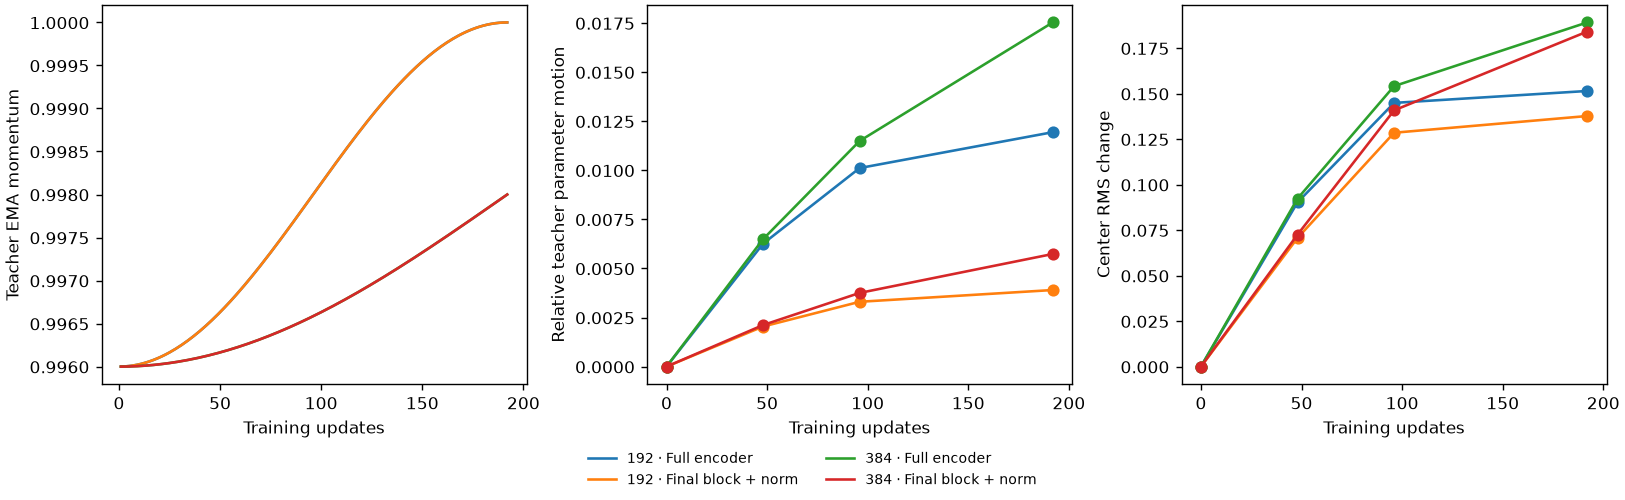

## Held-out native loss and centering at 192

| Horizon and policy | Regime | Student loss | Teacher loss | Target entropy | Target argmax count | Center norm | Center shift RMS |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 192 · Full encoder | A | 11.091 | 11.541 | 10.935 | 5.7 | 27.186 | 0.15146 |
| 192 · Full encoder | B | 11.115 | 10.901 | 9.447 | 2.7 | 27.186 | 0.15146 |
| 192 · Full encoder | C | 11.011 | 10.917 | 10.093 | 4.0 | 27.186 | 0.15146 |
| 192 · Full encoder | D | 11.135 | 10.984 | 10.153 | 4.3 | 27.186 | 0.15146 |
| 192 · Final block + norm | A | 11.098 | 11.267 | 10.548 | 6.0 | 30.519 | 0.13770 |
| 192 · Final block + norm | B | 11.013 | 10.877 | 9.294 | 2.7 | 30.519 | 0.13770 |
| 192 · Final block + norm | C | 10.890 | 10.845 | 9.924 | 4.0 | 30.519 | 0.13770 |
| 192 · Final block + norm | D | 10.912 | 10.843 | 9.948 | 2.7 | 30.519 | 0.13770 |
| 384 · Full encoder | A | 11.086 | 11.231 | 11.063 | 5.3 | 17.654 | 0.18914 |
| 384 · Full encoder | B | 11.096 | 11.186 | 10.606 | 3.7 | 17.654 | 0.18914 |
| 384 · Full encoder | C | 11.070 | 11.174 | 10.893 | 4.0 | 17.654 | 0.18914 |
| 384 · Full encoder | D | 11.095 | 11.198 | 10.884 | 4.7 | 17.654 | 0.18914 |
| 384 · Final block + norm | A | 11.098 | 11.212 | 10.961 | 6.3 | 18.688 | 0.18411 |
| 384 · Final block + norm | B | 11.027 | 11.015 | 9.996 | 3.0 | 18.688 | 0.18411 |
| 384 · Final block + norm | C | 10.993 | 10.989 | 10.560 | 3.7 | 18.688 | 0.18411 |
| 384 · Final block + norm | D | 11.014 | 10.964 | 10.524 | 3.3 | 18.688 | 0.18411 |

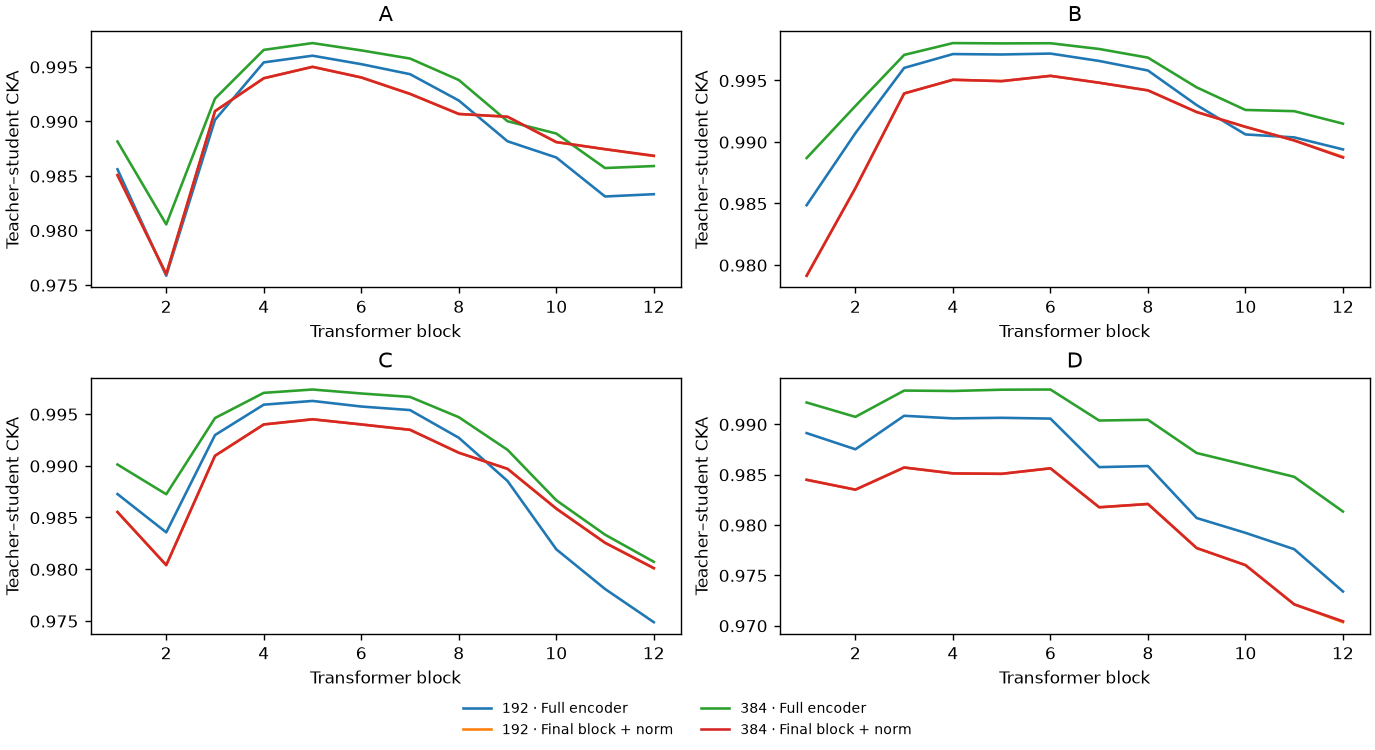

Layer-wise drift and variance are measured at every checkpoint and saved in the audit receipts. This table shows the terminal block.

| Horizon and policy | Regime | Teacher drift | Student drift | Teacher variance | Student variance |
| --- | --- | --- | --- | --- | --- |
| 192 · Full encoder | A | 0.001466 | 0.016246 | 0.005116 | 0.004026 |
| 192 · Full encoder | B | 0.000933 | 0.006997 | 0.003872 | 0.002992 |
| 192 · Full encoder | C | 0.001534 | 0.013843 | 0.005238 | 0.003988 |
| 192 · Full encoder | D | 0.003627 | 0.016178 | 0.002702 | 0.002296 |
| 192 · Final block + norm | A | 0.000017 | 0.000051 | 0.005792 | 0.004222 |
| 192 · Final block + norm | B | 0.000022 | 0.000033 | 0.004350 | 0.003176 |
| 192 · Final block + norm | C | 0.000022 | 0.000042 | 0.005893 | 0.004307 |
| 192 · Final block + norm | D | 0.000022 | 0.000061 | 0.002999 | 0.002226 |
| 384 · Full encoder | A | 0.003450 | 0.017985 | 0.004819 | 0.004053 |
| 384 · Full encoder | B | 0.002167 | 0.007884 | 0.003655 | 0.003004 |
| 384 · Full encoder | C | 0.004015 | 0.014478 | 0.004924 | 0.004008 |
| 384 · Full encoder | D | 0.007843 | 0.016292 | 0.002578 | 0.002322 |
| 384 · Final block + norm | A | 0.000036 | 0.000050 | 0.005793 | 0.004221 |
| 384 · Final block + norm | B | 0.000045 | 0.000032 | 0.004352 | 0.003175 |
| 384 · Final block + norm | C | 0.000046 | 0.000044 | 0.005896 | 0.004306 |
| 384 · Final block + norm | D | 0.000046 | 0.000060 | 0.002998 | 0.002226 |

## B · Controlled replication across 8/8 fresh walks

### Teacher · change from frozen (pp)

| Policy | Updates | A | B |
| --- | --- | --- | --- |
| Full encoder | 0 | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Full encoder | 48 | +0.605 [+0.487, +0.726] | +0.185 [+0.074, +0.274] |
| Full encoder | 96 | +0.742 [+0.610, +0.878] | +0.391 [+0.193, +0.565] |
| Full encoder | 192 | +0.430 [+0.242, +0.599] | -0.037 [-0.205, +0.148] |
| Final block + norm | 0 | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Final block + norm | 48 | -0.007 [-0.033, +0.013] | +0.137 [+0.108, +0.171] |
| Final block + norm | 96 | +0.062 [+0.011, +0.108] | +0.288 [+0.185, +0.383] |
| Final block + norm | 192 | +0.166 [+0.077, +0.250] | +0.535 [+0.428, +0.638] |

| 192-update contrast | Paired effect (pp) | Walk and capture interval (pp) |
| --- | --- | --- |
| A full minus last | +0.264 [+0.007, +0.500] | — |
| B last minus full | +0.572 [+0.342, +0.804] | — |
| A full minus frozen | +0.430 [+0.242, +0.599] | — |
| B last minus frozen | +0.535 [+0.428, +0.638] | — |

### Student · change from frozen (pp)

| Policy | Updates | A | B |
| --- | --- | --- | --- |
| Full encoder | 0 | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Full encoder | 48 | -0.294 [-0.664, +0.018] | +0.892 [+0.394, +1.340] |
| Full encoder | 96 | -0.300 [-0.834, +0.137] | +0.748 [+0.221, +1.211] |
| Full encoder | 192 | -0.335 [-0.870, +0.182] | +0.895 [+0.227, +1.497] |
| Final block + norm | 0 | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Final block + norm | 48 | +0.003 [-0.105, +0.119] | -0.033 [-0.160, +0.076] |
| Final block + norm | 96 | -0.011 [-0.134, +0.114] | +0.029 [-0.111, +0.185] |
| Final block + norm | 192 | -0.064 [-0.222, +0.089] | +0.057 [-0.049, +0.164] |

| 192-update contrast | Paired effect (pp) | Walk and capture interval (pp) |
| --- | --- | --- |
| A full minus last | -0.271 [-0.837, +0.274] | [-1.407, +0.954] |
| B last minus full | -0.837 [-1.475, -0.129] | [-1.991, +0.287] |
| A full minus frozen | -0.335 [-0.870, +0.182] | [-1.602, +1.003] |
| B last minus frozen | +0.057 [-0.049, +0.164] | [-0.386, +0.481] |

**Student trade-off gate missed.**